# Part A: Dataset Loading & Basic Inspection
# Import required libraries


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('taitanic.csv')

# Display first 10 rows
print(df.head(10))

# Display last 10 rows

print(df.tail(10))
# Print shape of dataset
print(df.shape)

# Print column names

print(df.columns)
# Print data types of each column

print(df.dtypes)
# Use .info() and explain what it shows

print(df.info())
# Use .describe() and explain what it shows

print(df.describe())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   
5            6         0       3   
6            7         0       1   
7            8         0       3   
8            9         1       3   
9           10         1       2   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   
5                                   Moran, Mr. James    male   NaN      0   
6                            McCarthy, Mr. Timothy J    male  54

# Part B: Missing Values Handling



In [5]:

# Find total missing values in each column
print(df.isnull().sum())

# Calculate missing value percentage for each column
print(df.isnull().mean()*100)

# Fill missing Age with median
df['Age']=df['Age'].fillna(df['Age'].median)
print(df['Age'])

# Fill missing Embarked with mode
df['Embarked']=df['Embarked'].fillna(df['Embarked'].mode()[0])
print(df['Embarked'])

# Fill missing Cabin with "Unknown"

df['Cabin']=df['Cabin'].fillna('Unknown')
print(df['Cabin'])
# Drop rows where Fare is missing (if any)
print(df.dropna(subset=['Fare'], inplace=True))

# Verify missing values are handled
print(df.isnull().sum().sum())


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64
0                                                   22.0
1                                                   38.0
2                                                   26.0
3                                                   35.0
4                                                   35.0
                             ...                        
886                                                 27.0
887                                          

# Part C: NumPy Integration & Statistical Analysis

In [8]:
import pandas as pd
import numpy as np

# Age ko numeric mein convert karke NaNs hata rahe hain taaki error na aaye
values = pd.to_numeric(df["Age"], errors='coerce').dropna().values
print(values)

# Ab mean, median, std waghera nikalenge
mean_age = np.mean(values)
median_age = np.median(values)
std_age = np.std(values)
var_age = np.var(values)
min_age = np.min(values)
max_age = np.max(values)

print(f"Mean Age: {mean_age}")
print(f"Median Age: {median_age}")
print(f"Standard Deviation of Age: {std_age}")
print(f"Variance of Age: {var_age}")
print(f"Minimum Age: {min_age}")
print(f"Maximum Age: {max_age}")

# Top 5 oldest passengers
print(np.sort(values)[-5:])

# Z-score normalization for Fare
fare = pd.to_numeric(df["Fare"], errors='coerce').to_numpy()
df["Fare_ZScore"] = (fare - np.mean(fare)) / np.std(fare)
print(df[["Fare", "Fare_ZScore"]].head())

[22.   38.   26.   35.   35.   54.    2.   27.   14.    4.   58.   20.
 39.   14.   55.    2.   31.   35.   34.   15.   28.    8.   38.   19.
 40.   66.   28.   42.   21.   18.   14.   40.   27.    3.   19.   18.
  7.   21.   49.   29.   65.   21.   28.5   5.   11.   22.   38.   45.
  4.   29.   19.   17.   26.   32.   16.   21.   26.   32.   25.    0.83
 30.   22.   29.   28.   17.   33.   16.   23.   24.   29.   20.   46.
 26.   59.   71.   23.   34.   34.   28.   21.   33.   37.   28.   21.
 38.   47.   14.5  22.   20.   17.   21.   70.5  29.   24.    2.   21.
 32.5  32.5  54.   12.   24.   45.   33.   20.   47.   29.   25.   23.
 19.   37.   16.   24.   22.   24.   19.   18.   19.   27.    9.   36.5
 42.   51.   22.   55.5  40.5  51.   16.   30.   44.   40.   26.   17.
  1.    9.   45.   28.   61.    4.    1.   21.   56.   18.   50.   30.
 36.    9.    1.    4.   45.   40.   36.   32.   19.   19.    3.   44.
 58.   42.   24.   28.   34.   45.5  18.    2.   32.   26.   16.   40.
 24

# Part D: Advanced Filtering & Conditional Selection

In [11]:
# Age column ko pehle strictly numeric bana lete hain taaki between() error na de
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')

# Male/Female survival counts
print(df[(df['Sex'] == 'male') & (df['Survived'] == 1)].shape[0])
print(df[(df['Sex'] == 'male') & (df['Survived'] == 0)].shape[0])
print(df[(df['Sex'] == 'female') & (df['Survived'] == 1)].shape[0])
print(df[(df['Sex'] == 'female') & (df['Survived'] == 0)].shape[0])

# Find passengers who paid Fare > 75 and Pclass = 1
print(df[(df['Fare'] > 75) & (df['Pclass'] == 1)])

# Find passengers whose Age is between 20 and 40 and Embarked from S
print(df[(df['Age'].between(20, 40)) & (df['Embarked'] == 'S')])

# Find passengers traveling alone (SibSp=0 and Parch=0)
print(df[(df['SibSp'] == 0) & (df['Parch'] == 0)])

109
468
233
81
     PassengerId  Survived  Pclass  \
27            28         0       1   
31            32         1       1   
34            35         0       1   
52            53         1       1   
61            62         1       1   
..           ...       ...     ...   
829          830         1       1   
835          836         1       1   
849          850         1       1   
856          857         1       1   
879          880         1       1   

                                               Name     Sex   Age  SibSp  \
27                   Fortune, Mr. Charles Alexander    male  19.0      3   
31   Spencer, Mrs. William Augustus (Marie Eugenie)  female   NaN      1   
34                          Meyer, Mr. Edgar Joseph    male  28.0      1   
52         Harper, Mrs. Henry Sleeper (Myna Haxtun)  female  49.0      1   
61                              Icard, Miss. Amelie  female  38.0      0   
..                                              ...     ...   ...    ...

# Part E: Feature Engineering

In [12]:

# Create FamilySize column
# FamilySize = SibSp + Parch + 1

df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
print(df["FamilySize"] )
# Create IsAlone column
# If FamilySize == 1 then 1 else 0

df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
print(df['IsAlone'])

# Extract Title from Name column
# Store it in a new column Title

df["Title"] =df['Name'].str.extract(' ([A-Za-z]+)\.')
print(df["Title"])
# Display the dataset after feature engineering

print(df.head())

0      2
1      2
2      1
3      2
4      1
      ..
886    1
887    1
888    4
889    1
890    1
Name: FamilySize, Length: 891, dtype: int64
0      0
1      0
2      1
3      0
4      1
      ..
886    1
887    1
888    0
889    1
890    1
Name: IsAlone, Length: 891, dtype: int64
0        Mr
1       Mrs
2      Miss
3       Mrs
4        Mr
       ... 
886     Rev
887    Miss
888    Miss
889      Mr
890      Mr
Name: Title, Length: 891, dtype: str
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. 

<>:15: SyntaxWarning: invalid escape sequence '\.'
<>:15: SyntaxWarning: invalid escape sequence '\.'
C:\Users\HP\AppData\Local\Temp\ipykernel_14036\2515690068.py:15: SyntaxWarning: invalid escape sequence '\.'
  df["Title"] =df['Name'].str.extract(' ([A-Za-z]+)\.')


# Part F: GroupBy, Aggregation & Pivot Tables

In [14]:
# Compute survival rate by Gender
print(df.groupby('Sex')['Survived'].mean())

# Compute survival rate by Pclass
print(df.groupby("Pclass")["Survived"].mean())

# Compute survival rate by Embarked
print(df.groupby('Embarked')['Survived'].mean())

# Compute survival rate by Age (bracket theek kar di hai)
print(df.groupby("Age")["Survived"].mean())

# Pivot Table: survival rate by Pclass and Sex
ss = pd.pivot_table(df, values="Survived", index="Pclass", columns='Sex', aggfunc='mean')
print(ss)

# Pivot Table: average Fare by Age and Pclass
ss = pd.pivot_table(df, values="Fare", index="Age", columns="Pclass", aggfunc="mean")
print(ss)

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64
Embarked
C    0.553571
Q    0.389610
S    0.339009
Name: Survived, dtype: float64
Age
0.42     1.0
0.67     1.0
0.75     1.0
0.83     1.0
0.92     1.0
        ... 
70.00    0.0
70.50    0.0
71.00    0.0
74.00    0.0
80.00    1.0
Name: Survived, Length: 88, dtype: float64
Sex       female      male
Pclass                    
1       0.968085  0.368852
2       0.921053  0.157407
3       0.500000  0.135447
Pclass         1       2        3
Age                              
0.42         NaN     NaN   8.5167
0.67         NaN  14.500      NaN
0.75         NaN     NaN  19.2583
0.83         NaN  23.875      NaN
0.92    151.5500     NaN      NaN
...          ...     ...      ...
70.00    71.0000  10.500      NaN
70.50        NaN     NaN   7.7500
71.00    42.0792     NaN      NaN
74.00        NaN     NaN   7.7750
80.00    30.0000     NaN      Na

# Part G: Outlier Detection using NumPy (Fare)

In [15]:
# Compute Q1, Q3, IQR for Fare using NumPy

q1 = np.percentile(df["Fare"], 25)
q3 = np.percentile(df["Fare"], 75)
iqr = q3 - q1
# Compute lower and upper outlier boundaries

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print(lower)
print(upper)
# Count how many Fare values are outliers
print(((df["Fare"] < lower) | (df["Fare"] > upper)).sum())

# Create Fare_Outlier column
# 1 if Fare is outlier else 0
df["Fare_Outlier"] = ((df["Fare"] < lower) | (df["Fare"] > upper)).astype(int)
print(df["Fare_Outlier"])

-26.724
65.6344
116
0      0
1      1
2      0
3      0
4      0
      ..
886    0
887    0
888    0
889    0
890    0
Name: Fare_Outlier, Length: 891, dtype: int64


PART H: Relationship Hunting (Hypothesis-First Rule)


--- SURVIVAL RATE BY PCLASS ---
   Pclass  Survived
0       1  0.629630
1       2  0.472826
2       3  0.242363


C:\Users\HP\AppData\Local\Temp\ipykernel_14036\3882538032.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Pclass', y='Survived', data=df, palette='viridis')


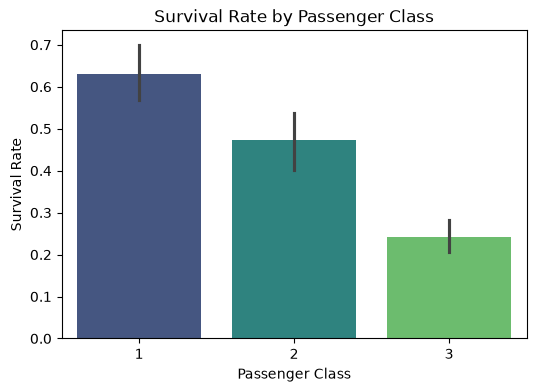

In [16]:
# Hypothesis: Higher passenger class (Pclass = 1) had higher survival rate.
pclass_survival = df.groupby('Pclass')['Survived'].mean().reset_index()
print("\n--- SURVIVAL RATE BY PCLASS ---")
print(pclass_survival)

plt.figure(figsize=(6, 4))
sns.barplot(x='Pclass', y='Survived', data=df, palette='viridis')
plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.show()

PART I: The Hidden Leakage Challenge

In [17]:
print("\n--- COLUMNS AVAILABLE FOR PREDICTION ---")
print(df.columns.tolist())


--- COLUMNS AVAILABLE FOR PREDICTION ---
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'Fare_ZScore', 'FamilySize', 'IsAlone', 'Title', 'Fare_Outlier']


PART J: Reproducibility Setup

In [19]:
import sys

print("\n--- REPRODUCIBILITY INFO ---")
print("Python Version:", sys.version)
print("Pandas Version:", pd.__version__)
print("Seaborn Version:", sns.__version__)

random_state = 42
print("Random State configured to:", random_state)


--- REPRODUCIBILITY INFO ---
Python Version: 3.13.16 (tags/v3.13.16:cbc944f, Sep 30 2026, 19:17:50) [MSC v.1944 64 bit (AMD64)]
Pandas Version: 3.0.6
Seaborn Version: 0.13.2
Random State configured to: 42
